In [8]:
import numpy as np
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.datasets import make_blobs  
from matplotlib import pyplot as plt 

In [2]:
clusters = [[6,6,6], [2,2,2], [3,9,9]]
X, y = make_blobs(centers = clusters, cluster_std = 0.70)

### Estimate Bandwidth

El parámetro de ancho de banda h determina el tamaño del vecindario alrededor de cada punto de datos, influyendo directamente en los resultados de la agrupación. La función estimate_bandwith tiene un parámetro quantile que indica cuantas distancias cercanas utiliza, por ejemplo *quantile = 0.2* indica que usa el 20% de las distancias más cercanas.

In [5]:
bandwidth = estimate_bandwidth(X,n_samples = 500)

Con el ancho de banda estimado se crea y entrena el modelo.

In [ ]:
ms = MeanShift(bandwidth = bandwidth)
ms.fit(X)

,bandwidth,np.float64(2.2598962820726505)
,seeds,None
,bin_seeding,False
,min_bin_freq,1
,cluster_all,True
,n_jobs,None
,max_iter,300


In [10]:
# results:
etiquetas = ms.labels_
centroides = ms.cluster_centers_
n_clusters = len(np.unique(etiquetas))

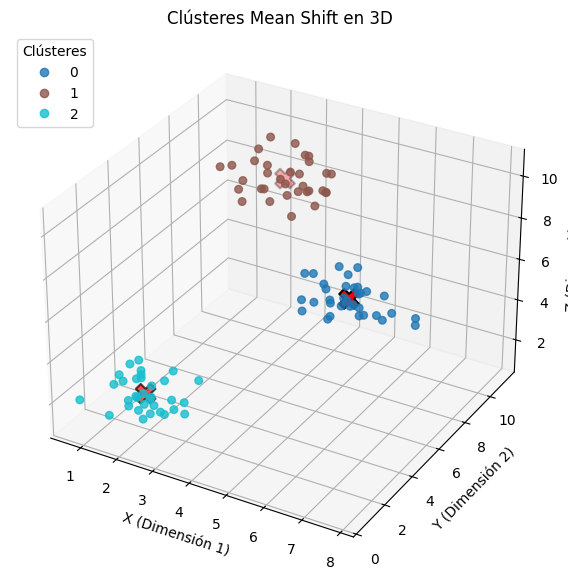

In [16]:
# Representación
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# 1. Graficar los puntos coloreados según su etiqueta de clúster
scatter = ax.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],  # Añadimos la tercera dimensión (eje Z)
    c=ms.labels_,  # Asigna un color distinto a cada grupo
    cmap="tab10",  # Paleta de colores bien diferenciados
    marker="o",
    s=30,
    alpha=0.8,
)

# 2. Graficar los centroides en 3D
ax.scatter(
    centroides[:, 0],
    centroides[:, 1],
    centroides[:, 2],  # Tercera dimensión de los centroides
    marker="X",
    color="red",
    s=200,
    edgecolors="black",
    linewidth=1.5,
    zorder=10,
    label="Centroides",
)

# 3. Añadir leyenda y etiquetas de ejes
ax.set_xlabel("X (Dimensión 1)")
ax.set_ylabel("Y (Dimensión 2)")
ax.set_zlabel("Z (Dimensión 3)")
ax.legend(*scatter.legend_elements(), title="Clústeres", loc="upper left")

plt.title("Clústeres Mean Shift en 3D")
plt.show()

## Conclusión

#### Ventajas principales

• Sin número fijo de clústeres. No requiere especificar de antemano cuántos grupos existen, ya que los descubre automáticamente según los picos de densidad de los datos.

• Adaptabilidad a formas arbitrarias. Al no asumir que los grupos son esféricos, identifica con éxito agrupaciones alargadas, irregulares o no convexas.

• Robustez frente al ruido. Es poco sensible a los valores atípicos (outliers), puesto que estos puntos aislados no logran desplazar los centros hacia zonas de alta densidad.

• Un único parámetro clave. Solo depende del ancho de banda (bandwidth o radio de la ventana), lo que simplifica su configuración inicial frente a algoritmos con múltiples hiperparámetros.

• Resultados deterministas. A diferencia de otros algoritmos que dependen de una inicialización aleatoria de centroides, Mean Shift siempre converge a las mismas modas para un mismo ancho de banda.


#### Inconvenientes y limitaciones

• Alto coste computacional. Su complejidad básica es cuadrática (O(n²)) respecto al número de muestras, lo que lo hace muy lento y poco escalable para bases de datos masivas.

• Sensibilidad al ancho de banda. Elegir el tamaño adecuado de la ventana es crítico. Un valor muy grande fusiona grupos distintos, mientras que uno muy pequeño fragmenta los datos en demasiados subgrupos.

• Bajo rendimiento en alta dimensionalidad. Cuando los datos tienen muchas variables o dimensiones, la estimación de densidad pierde precisión y el cálculo de distancias se vuelve ineficiente.

• Dificultad con densidades variables. Como utiliza un único radio de ventana global, le cuesta separar correctamente grupos que tienen densidades muy diferentes entre sí.